# Ejercicio de Normalización
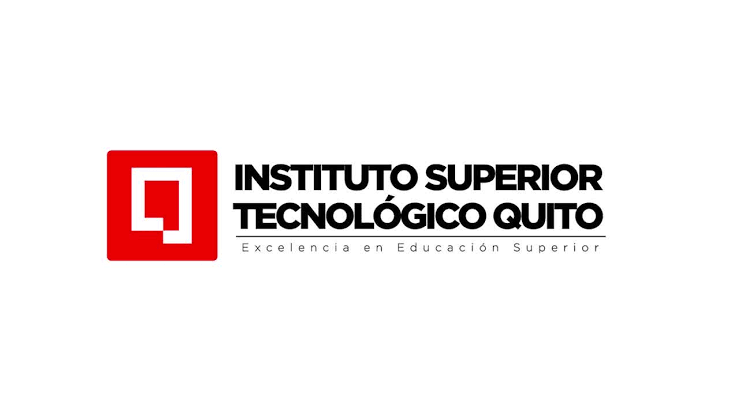

**Convertir los datos de entrada en un rango de 0 y 1, a este proceso le llamamos homotecia.**

**Fórmula:**

$$
x_{normalizado} = \frac{x - x_{min}}{x_{max} - x_{min}}
$$

**Nombre:** Vinicio Sarabia 

**Fecha:** 04-11-2026

**Link:** <a href="https://github.com/viniciosarabia68-arch/Practicas-Maching-Learning" target="_blank">Mi repositorio de GitHub</a>

In [1]:
#Importacion de librerias
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

### Explicación: importación de librerías
Se cargan las herramientas que se utilizarán en el ejercicio. **pandas** organiza los datos en tablas; **NumPy** permite trabajar con números y arreglos; **load_iris** ofrece una versión del conjunto Iris desde scikit-learn (aunque en este notebook los datos se leen desde un CSV); **zipfile** sirve para manejar archivos ZIP; **seaborn** y **matplotlib** permiten crear gráficos; y **preprocessing** contiene las técnicas de normalización y estandarización.

**¿Para qué sirven?** Para leer, explorar, transformar y representar los datos antes de utilizarlos en un modelo de aprendizaje automático.

In [2]:
#Configuramos el entorno de descarga
import os
os.environ['KAGGLE_CONFIG_DIR'] = "C:/Users/ADMIN-ITQ/.kaggle"

### Explicación: ruta de configuración de Kaggle
`os.environ['KAGGLE_CONFIG_DIR']` indica dónde debe buscar Kaggle sus credenciales de acceso. En esta celda se establece la carpeta `C:/Users/ADMIN-ITQ/.kaggle` de Windows.

**¿Para qué sirve?** Para que Kaggle pueda autenticarse al descargar datasets. La carpeta debe existir y contener credenciales válidas; nunca se deben publicar las claves.

In [22]:
#Creamos la carpeta dataset
os.makedirs("dataset", exist_ok=True)

### Explicación: creación de la carpeta de trabajo
`os.makedirs('dataset', exist_ok=True)` crea una carpeta llamada **dataset** dentro del directorio de trabajo actual. Si ya existe, `exist_ok=True` evita que se produzca un error.

**¿Para qué sirve?** Para mantener organizados los archivos de datos. **Importante:** crear la carpeta no mueve automáticamente los archivos descargados a ella.

In [35]:
#Descargamos el dataset
!kaggle datasets download -d uciml/iris

Dataset URL: https://www.kaggle.com/datasets/uciml/iris
License(s): CC0-1.0
iris.zip: Skipping, found more recently modified local copy (use --force to force download)


### Explicación: descarga del dataset Iris
El comando `!kaggle datasets download -d uciml/iris` solicita a Kaggle el conjunto de datos **Iris**. El símbolo `!` permite ejecutar un comando de terminal desde Jupyter.

**¿Para qué sirven estos datos?** Iris contiene mediciones de sépalos y pétalos de flores y una categoría de especie. Se utiliza para practicar clasificación y preprocesamiento.

**Atención:** la descarga suele generar un archivo ZIP en el directorio actual. Esta celda no lo descomprime ni lo coloca en `dataset/`; para que la lectura posterior funcione, `dataset/Iris.csv` debe existir.

In [32]:
#Configuramos el entorno de descarga
import os

os.environ['KAGGLE_CONFIG_DIR'] = os.path.expanduser("~/.kaggle")
os.makedirs(os.environ['KAGGLE_CONFIG_DIR'], exist_ok=True)

### Explicación: segunda configuración de Kaggle
`os.path.expanduser('~/.kaggle')` obtiene la carpeta `.kaggle` del usuario con el que se ejecuta Python, y `os.makedirs` se asegura de que exista.

**¿Para qué sirve?** Para localizar la configuración de Kaggle de manera dependiente del usuario. **Importante:** esta celda reemplaza la ruta fijada anteriormente (`C:/Users/ADMIN-ITQ/.kaggle`). Si son carpetas diferentes, la autenticación podría fallar; crear la carpeta tampoco crea las credenciales.

In [33]:
#Descargamos el dataset
import sys
!{sys.executable} -m kaggle datasets download -d uciml/iris

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Dataset URL: https://www.kaggle.com/datasets/uciml/iris
License(s): CC0-1.0
iris.zip: Skipping, found more recently modified local copy (use --force to force download)


### Explicación: descarga usando el Python del notebook
`sys.executable` identifica el intérprete de Python activo en Jupyter. El comando `-m kaggle datasets download -d uciml/iris` ejecuta Kaggle con ese intérprete para descargar Iris.

**¿Para qué sirve?** Para evitar confusiones cuando Anaconda tiene varios entornos de Python. Al igual que la descarga anterior, el comando no descomprime automáticamente el ZIP ni garantiza que `dataset/Iris.csv` esté disponible.

In [25]:
 #Cargamos el conjunto de datos
df = pd.read_csv("dataset/Iris.csv")

### Explicación: lectura del archivo CSV
`pd.read_csv('dataset/Iris.csv')` abre el archivo de datos y lo guarda en `df`, un **DataFrame** de pandas: una tabla con filas (flores) y columnas (características).

**¿Para qué sirve?** Para poder analizar las medidas de cada flor y su especie. La ruta indicada debe existir; de lo contrario aparecerá `FileNotFoundError`.

In [26]:
#mostramos el conjunto de datos"
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Explicación: primeras filas de la tabla
`df.head()` muestra, por defecto, las **primeras cinco filas** del dataset.

**¿Qué significan los datos?** Cada fila representa una flor Iris. Las columnas de longitud y anchura de sépalo y pétalo describen sus medidas; `Species` indica la especie. Si aparece `Id`, es un identificador de fila.

**¿Para qué sirve?** Para comprobar que el CSV se cargó correctamente y conocer la estructura de los datos antes de transformarlos.

In [37]:
#Eliminamos columnas innecesarias en la limpieza de datos como vemos en el dataframe la columna id no aporta
#nada a nuestro modelo por lo tanto lo eliminamos
if 'Id' in df.columns:
    df=df.drop(columns=["Id"])

### Explicación: eliminación de una columna innecesaria
La condición `if 'Id' in df.columns` comprueba si existe la columna **Id**. Si existe, `df.drop(columns=['Id'])` la elimina y guarda el resultado en `df`.

**¿Para qué sirve?** El identificador solo distingue registros; no es una medida física de la flor y normalmente no debe utilizarse para predecir la especie. Esta celda no muestra una tabla nueva por sí sola.

In [38]:
#Mostramos los detalles de nuesto dataset
df.info()
#Vrificamos si tenemos datos nulos si lo tenemos lo sumamos
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

### Explicación: estructura y valores faltantes
`df.info()` informa del número de filas, nombres de columnas, cantidad de valores no nulos y tipos de datos. `df.isnull().sum()` cuenta los valores faltantes de cada columna.

**¿Cómo interpretar el resultado?** Un **0** en el conteo de nulos significa que esa columna no tiene valores faltantes. Si aparece un número mayor que cero, hay registros incompletos que podrían requerir limpieza.

**¿Para qué sirve?** Para verificar la calidad y los tipos de datos antes del análisis. En Jupyter, la última expresión suele mostrarse como tabla de conteos.

In [39]:
#Separamos los datos de entrada con nuestra variable objetivo
X=df.drop(columns=['Species'])
y=df['Species']

### Explicación: variables de entrada y variable objetivo
`X = df.drop(columns=['Species'])` guarda las **características de entrada** (medidas de la flor). `y = df['Species']` guarda la **variable objetivo**, es decir, la especie que se quiere predecir.

**¿Para qué sirve?** Para separar la información que usaría un modelo de clasificación de la respuesta correcta que el modelo intentaría aprender. Esta celda solo crea variables; no entrena un modelo.

In [40]:
 #Exploramos o generamos un analis exploratorio del conjutno de datos
X.describe()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Explicación: estadísticas descriptivas
`X.describe()` crea una tabla de resumen para las variables numéricas: **count** (cantidad de valores), **mean** (promedio), **std** (desviación estándar), **min** (mínimo), **25%**, **50%** (mediana), **75%** (cuartiles) y **max** (máximo).

**¿Para qué sirven estos datos?** Para conocer los rangos, valores centrales y dispersión de las medidas de las flores; esto ayuda a detectar diferencias de escala antes de normalizar.

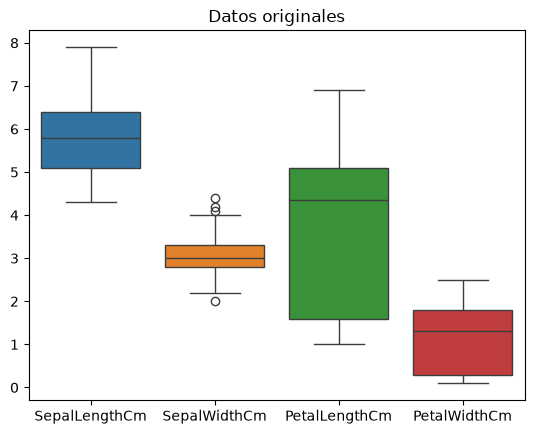

In [41]:
#dibujamso los datos originales
sns.boxplot(data=X)
#Ponemos un titulo a la imagen
plt.title("Datos originales")
plt.show()


### Explicación: diagrama de cajas de los datos originales
`sns.boxplot(data=X)` dibuja una caja por cada característica numérica. La línea dentro de cada caja indica la **mediana**; la caja abarca del primer al tercer cuartil; los bigotes muestran el rango según la regla del gráfico y los puntos aislados pueden representar **valores atípicos**.

**¿Para qué sirve?** Para comparar la dispersión de las medidas originales y detectar posibles valores extremos. Las variables aún conservan sus unidades y escalas originales.

In [42]:
#Normalizamos el conjunto de datos
normalizer = preprocessing.MinMaxScaler()
X_norm=normalizer.fit_transform(X)
X_norm = pd.DataFrame(X_norm, columns=X.columns)
X_norm.head()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


### Explicación: normalización Min-Max
`preprocessing.MinMaxScaler()` crea un transformador que ajusta cada característica numérica al intervalo **0 a 1**, usando su mínimo y máximo observados. `fit_transform(X)` calcula esos extremos y transforma los valores. Después, `pd.DataFrame(..., columns=X.columns)` recupera los nombres de las columnas.

**Fórmula:** $x_{norm} = \frac{x-x_{min}}{x_{max}-x_{min}}$.

**¿Qué significa la tabla `X_norm.head()`?** Muestra las primeras cinco flores con medidas normalizadas: 0 corresponde al mínimo de esa característica y 1 al máximo observado.

**¿Para qué sirve?** Para poner variables con rangos distintos en una escala comparable. No cambia la columna `Species`, ya que se trabaja únicamente con `X`.

In [43]:
X_norm.describe()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,0.428704,0.439167,0.467571,0.457778
std,0.230018,0.180664,0.299054,0.317984
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.567797,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


### Explicación: estadísticas de los datos normalizados
`X_norm.describe()` muestra el resumen estadístico de las características después de aplicar Min-Max.

**¿Cómo interpretar la tabla?** Los valores **min** suelen ser 0 y **max** suelen ser 1 para cada columna no constante. `mean`, `std` y los cuartiles expresan ahora la distribución en la nueva escala.

**¿Para qué sirve?** Para comprobar que la normalización se realizó y comparar sus resultados con `X.describe()`.

In [44]:
 #Estaddarización
standarizer = preprocessing.StandardScaler()
#Estandarizamos los datos
X_std=standarizer.fit_transform(X)
X_std= pd.DataFrame(X_std, columns=X.columns)
X_std.head()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


### Explicación: estandarización con StandardScaler
`preprocessing.StandardScaler()` crea un transformador que resta la media de cada característica y divide entre su desviación estándar. `fit_transform(X)` calcula esas estadísticas y transforma las medidas; luego se crea el DataFrame `X_std`.

**Fórmula:** $z = \frac{x-\mu}{\sigma}$.

**¿Qué significa `X_std.head()`?** Muestra las primeras cinco flores con valores estandarizados. Un valor **positivo** está por encima de la media de esa característica; uno **negativo**, por debajo.

**¿Para qué sirve?** Para centrar las variables aproximadamente en media 0 y desviación estándar 1, algo útil en muchos métodos de aprendizaje automático. A diferencia de Min-Max, los resultados no están limitados al intervalo 0–1.

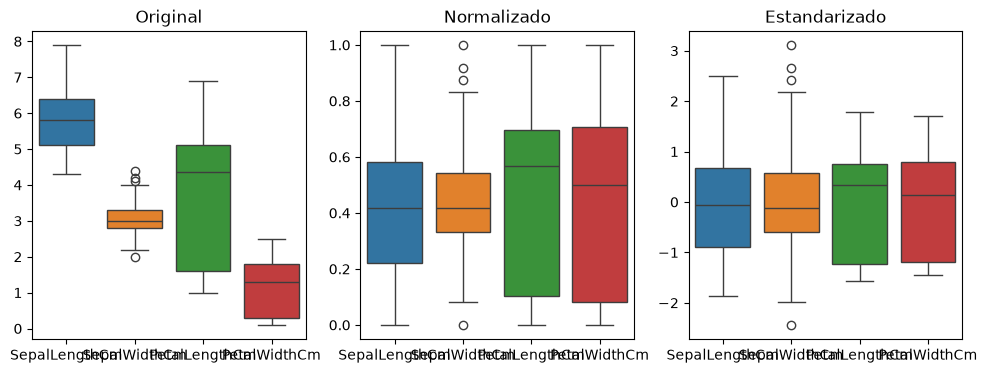

In [45]:
#Comporación visual
plt.figure(figsize=(12,4))
3
plt.subplot(1,3,1)
sns.boxplot(data=X)
plt.title("Original")
plt.subplot(1,3,2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.subplot(1,3,3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.show()


### Explicación: comparación visual de las tres escalas
`plt.figure(figsize=(12,4))` prepara la figura y `plt.subplot(1,3,...)` crea tres espacios. Los gráficos de cajas comparan **Original** (`X`), **Normalizado** (`X_norm`) y **Estandarizado** (`X_std`). `plt.show()` presenta la figura.

**¿Qué significa cada gráfico?** **Original:** muestra las medidas en su escala inicial. **Normalizado:** sitúa cada característica entre 0 y 1. **Estandarizado:** muestra valores centrados alrededor de 0, con posibles valores negativos y mayores que 1.

**¿Para qué sirve?** Para observar cómo cambia la escala sin alterar el orden relativo de las observaciones de cada característica. La línea `3` que aparece sola en el código no modifica el gráfico.